In [1]:
%pip install tensorflow matplotlib scikit-learn 

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import pandas as pd

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.datasets import cifar10
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report


In [3]:
np.random.seed(42)
tf.random.set_seed(42)

In [4]:
(X_all_images, y_all_labels), (X_test_images, y_test_labels) = cifar10.load_data()

y_all_labels = y_all_labels.flatten()
y_test_labels = y_test_labels.flatten()
print("Original training data:", X_all_images.shape)
print("Clean test data:", X_test_images.shape)

Original training data: (50000, 32, 32, 3)
Clean test data: (10000, 32, 32, 3)


In [5]:
#selecting 500 images( 50 from each of the 10 classes)
np.random.seed(42)
selected = []
for classes in range(10):
    ids = np.where(y_all_labels == classes)[0]
    chosen = np.random.choice(ids, 50, replace=False)
    selected = selected + list(chosen)
    
X_small = X_all_images[selected]
y_small = y_all_labels[selected]
print("Selected images:", X_small.shape)

Selected images: (500, 32, 32, 3)


In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X_small,
    y_small,
    test_size=100, #100 validation images and the rest of 400 are training images
    random_state=42,
    stratify=y_small
)
print("training images:", X_train.shape)
print("validation images:", X_val.shape)

training images: (400, 32, 32, 3)
validation images: (100, 32, 32, 3)


In [7]:
#scipy for image rotation
%pip install scipy 

Note: you may need to restart the kernel to use updated packages.


In [8]:
from scipy.ndimage import rotate
def corrupt_image(image, rng, hidden=False): #receives one clean image and creates a corrupted version of it
    image = image.astype(np.float32) / 255.0
    angle = rng.uniform(-25, 25) #random rotation of up to ±25°
    image = rotate(
        image, angle, axes=(1, 0),
        reshape=False, mode='nearest'
    )
    contrast = rng.uniform(0.7, 1.3) 
    brightness = rng.uniform(-0.2, 0.2)
    image = (image - 0.5) * contrast + 0.5 + brightness
    image = np.clip(image, 0, 1)
    #random rectangular occlusion (about 25% of the image)
    h, w = 16, 16
    top = rng.integers(0, 32 - h + 1)
    left = rng.integers(0, 32 - w + 1)
    image[top:top+h, left:left+w] = 0
    # Hidden corruption: grayscale
    if hidden:
        gray = np.mean(image, axis=2, keepdims=True)
        image = np.repeat(gray, 3, axis=2)

    return (image * 255).astype(np.uint8)

In [9]:
rng = np.random.default_rng(2026) #seed 2026 makes random number choices repeatedly
X_shifted = np.empty_like(X_test_images)
hidden_ids = rng.choice(
    len(X_test_images), len(X_test_images) // 5, replace=False #hidden corruption applied to 20% of the 10000 test images
) 
for i in range(len(X_test_images)):
    hidden = i in hidden_ids
    X_shifted[i] = corrupt_image(X_test_images[i], rng, hidden) #Loops through every test image and calls corrupt_image()

y_shifted = y_test_labels.copy() #labels are copied exactly the same, only images corrupted
print(X_shifted.shape)
print(len(hidden_ids))

(10000, 32, 32, 3)
2000


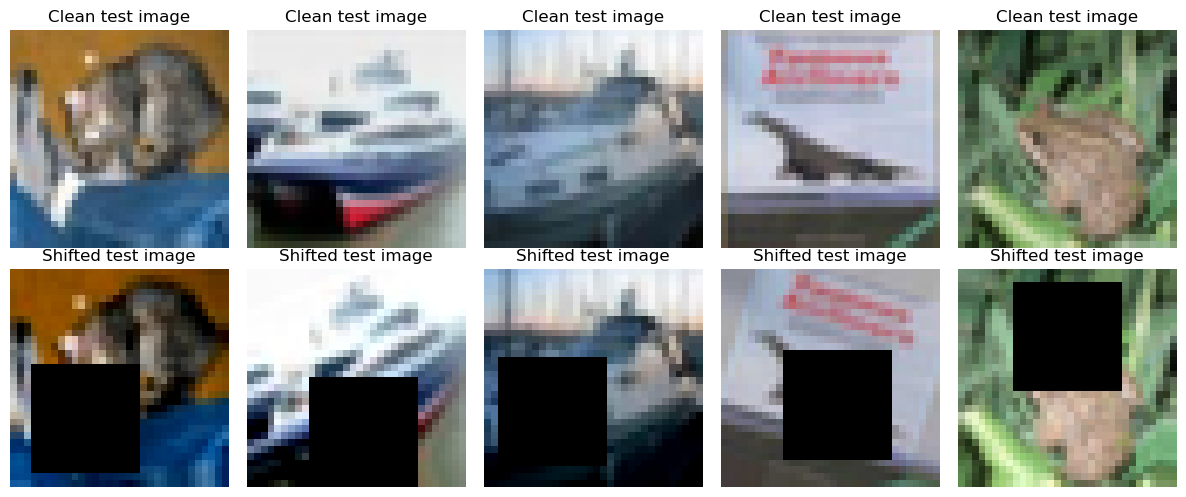

In [10]:
#comparison of clean and shifted images:
plt.figure(figsize=(12, 5))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test_images[i])
    plt.title("Clean test image")
    plt.axis('off')

    plt.subplot(2, 5, i + 6)
    plt.imshow(X_shifted[i])
    plt.title("Shifted test image")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [11]:
#defining one inception module:
def inception_module(x):
    branch1 = layers.Conv2D(
        16, (1, 1), padding='same', activation='relu'
    )(x)
    branch3 = layers.Conv2D(
        16, (1, 1), padding='same', activation='relu'
    )(x)
    branch3 = layers.Conv2D(
        24, (3, 3), padding='same', activation='relu'
    )(branch3)
    branch5 = layers.Conv2D(
        8, (1, 1), padding='same', activation='relu'
    )(x)
    branch5 = layers.Conv2D(
        12, (5, 5), padding='same', activation='relu'
    )(branch5)

    return layers.Concatenate()([branch1, branch3, branch5])

In [12]:
#building the complete CNN now:
inputs = layers.Input(shape=(32, 32, 3))
x = layers.Rescaling(1./255)(inputs)
x = layers.Conv2D(
    32, (3, 3), padding='same', use_bias=False
)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = inception_module(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(
    64, (3, 3), padding='same', activation='relu'
)(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(
    64, activation='relu',
    kernel_regularizer=regularizers.l2(0.001)
)(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(10, activation='softmax')(x)
model = models.Model(inputs, outputs)

In [13]:
model.summary()
print("Trainable parameters:", model.count_params())

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ rescaling (Rescaling)         │ (None, 32, 32, 3)         │               0 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 32, 32, 32)        │             864 │ rescaling[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 32, 32, 32)        │             128 │ conv2d[0][0]               │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 32, 32, 32)        │               0 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 16, 16, 32)        │               0 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 16, 16, 16)        │             528 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_4 (Conv2D)             │ (None, 16, 16, 8)         │             264 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 16, 16, 16)        │             528 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 16, 16, 24)        │           3,480 │ conv2d_2[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_5 (Conv2D)             │ (None, 16, 16, 12)        │           2,412 │ conv2d_4[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 16, 16, 52)        │               0 │ conv2d_1[0][0],            │
│                               │                           │                 │ conv2d_3[0][0],            │
│                               │                           │                 │ conv2d_5[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 16, 16, 52)        │             208 │ concatenate[0][0]          │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_1               │ (None, 8, 8, 52)          │               0 │ batch_normalization_1[0][… │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_6 (Conv2D)             │ (None, 8, 8, 64)          │          30,01

 Total params: 43,238 (168.90 KB)

 Trainable params: 43,070 (168.24 KB)

 Non-trainable params: 168 (672.00 B)

Trainable parameters: 43238


In [14]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [15]:
#Now Part A: baseline training (no augmentation):
tf.keras.utils.set_random_seed(42) #uses only the 400 original training images
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 98ms/step - accuracy: 0.1550 - loss: 2.3740 - val_accuracy: 0.1100 - val_loss: 2.3630
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.2100 - loss: 2.2171 - val_accuracy: 0.1100 - val_loss: 2.3592
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.2150 - loss: 2.1530 - val_accuracy: 0.1400 - val_loss: 2.3497
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.2475 - loss: 2.0644 - val_accuracy: 0.1700 - val_loss: 2.3432
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.2750 - loss: 2.0124 - val_accuracy: 0.1700 - val_loss: 2.3349
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.2900 - loss: 1.9608 - val_accuracy: 0.1600 - val_loss: 2.3419
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.3500 - loss: 1.8591 - val_accuracy: 0.1300 - val_loss: 2.3492
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.3625 - loss: 1.7890 - val_accuracy: 0.1200 - v

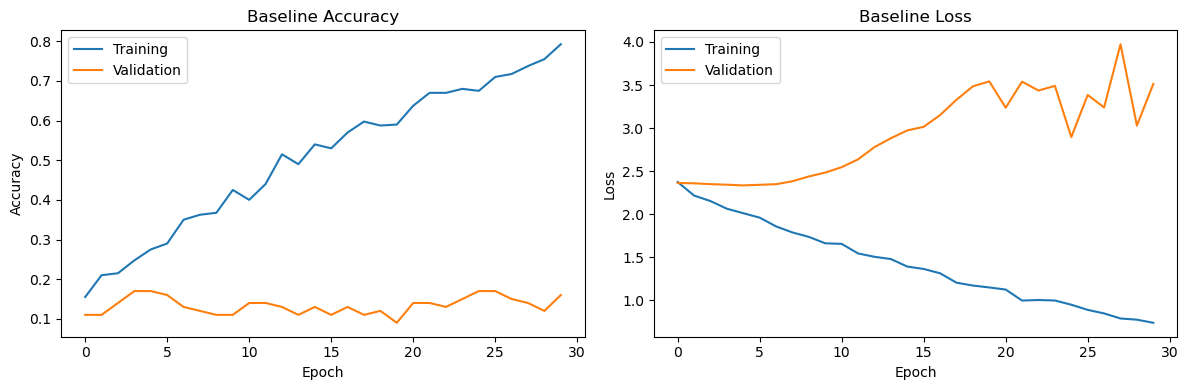

In [16]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Baseline Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Baseline Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
train_loss, train_acc = model.evaluate(
    X_train, y_train, verbose=0
)
val_loss, val_acc = model.evaluate(
    X_val, y_val, verbose=0
)
print("Training accuracy on 400 training images :", train_acc)
print("Validation accuracy on 100 images:", val_acc)

Training accuracy on 400 training images : 0.23999999463558197
Validation accuracy on 100 images: 0.1599999964237213


In [18]:

# Part A: Baseline results for three seeds
seeds = [42, 123, 2026]
train_accuracies = []
val_accuracies = []
baseline_histories = []
for seed in seeds:
    print("Running seed:", seed)
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    inputs = layers.Input(shape=(32, 32, 3))
    x = layers.Rescaling(1./255)(inputs)
    x = layers.Conv2D(
        32, 3, padding="same", activation="relu"
    )(x)
    x = layers.MaxPooling2D(2)(x)
    x = inception_module(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(
        64, 3, padding="same", activation="relu"
    )(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = models.Model(inputs, outputs)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    history = model.fit(
        X_train, y_train,
        epochs=30,
        batch_size=32,
        validation_data=(X_val, y_val),
        verbose=0
    )
    baseline_histories.append(history.history)
    _, train_acc = model.evaluate(
        X_train, y_train, verbose=0
    )
    _, val_acc = model.evaluate(
        X_val, y_val, verbose=0
    )
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    print("Training accuracy:", round(train_acc, 4))
    print("Validation accuracy:", round(val_acc, 4))

print("\nBaseline results across three seeds")
print("Training accuracy: %.4f +/- %.4f" % (
    np.mean(train_accuracies), np.std(train_accuracies)
))
print("Validation accuracy: %.4f +/- %.4f" % (
    np.mean(val_accuracies), np.std(val_accuracies)
))

Running seed: 42

Training accuracy: 0.335
Validation accuracy: 0.31
Running seed: 123
Training accuracy: 0.325
Validation accuracy: 0.28
Running seed: 2026
Training accuracy: 0.2975
Validation accuracy: 0.25

Baseline results across three seeds
Training accuracy: 0.3192 +/- 0.0159
Validation accuracy: 0.2800 +/- 0.0245


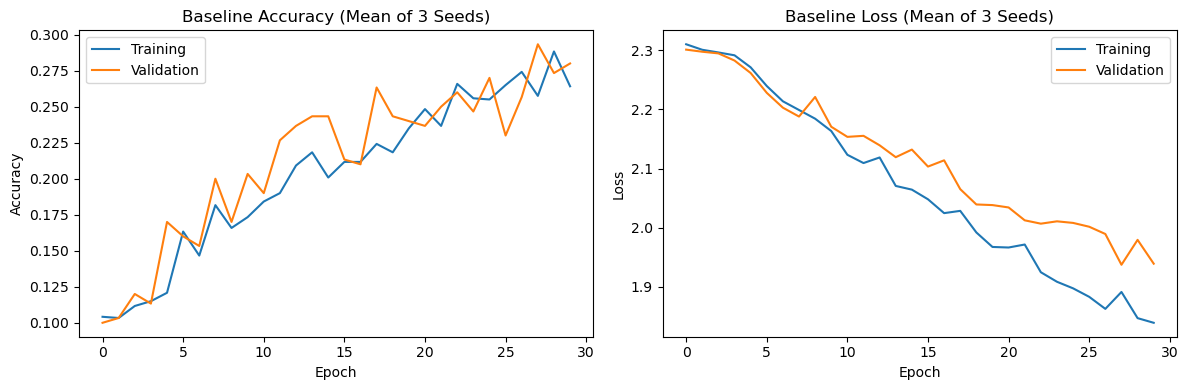

In [19]:

# Average learning curves across three seeds
train_acc_curve = np.mean(
    [h["accuracy"] for h in baseline_histories], axis=0
)
val_acc_curve = np.mean(
    [h["val_accuracy"] for h in baseline_histories], axis=0
)
train_loss_curve = np.mean(
    [h["loss"] for h in baseline_histories], axis=0
)
val_loss_curve = np.mean(
    [h["val_loss"] for h in baseline_histories], axis=0
)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_acc_curve, label="Training")
plt.plot(val_acc_curve, label="Validation")
plt.title("Baseline Accuracy (Mean of 3 Seeds)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(train_loss_curve, label="Training")
plt.plot(val_loss_curve, label="Validation")
plt.title("Baseline Loss (Mean of 3 Seeds)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# Part B:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(
        factor=25/360,
        fill_mode="reflect"
    ),
    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="reflect"
    ),
    layers.RandomZoom(
        height_factor=(-0.1, 0.1),
        width_factor=(-0.1, 0.1),
        fill_mode="reflect"
    ),
    layers.RandomBrightness(
        factor=0.15,
        value_range=(0, 255)
    ),
    layers.RandomContrast(0.2)
], name="data_augmentation")

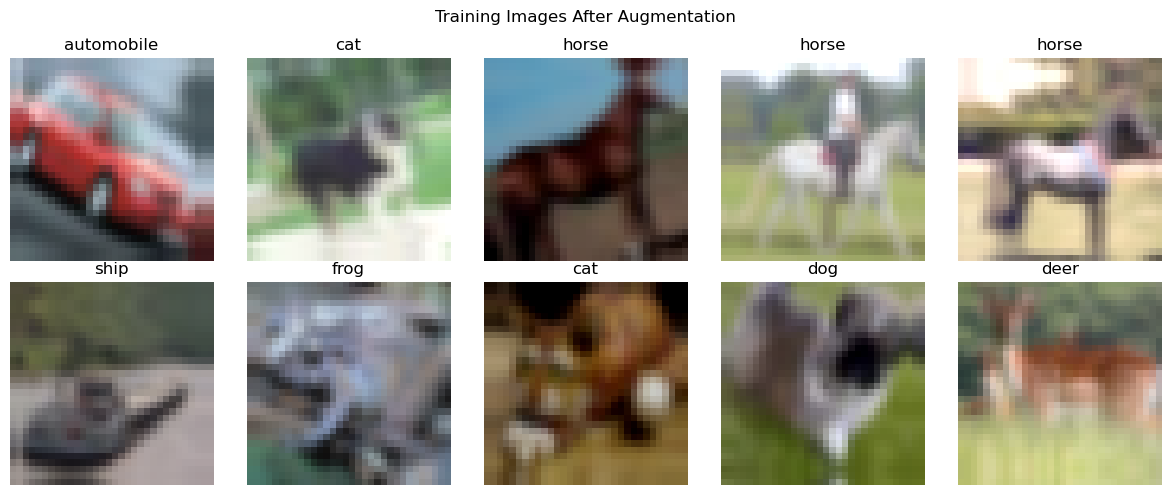

In [21]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
augmented_images = data_augmentation(
    X_train[:10],
    training=True
).numpy()

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = np.clip(
        augmented_images[i], 0, 255
    ).astype(np.uint8)

    plt.imshow(image)
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.suptitle("Training Images After Augmentation")
plt.tight_layout()
plt.show()

In [22]:
#build augmented model now:
inputs = layers.Input(shape=(32, 32, 3))
x = data_augmentation(inputs)
# Normalize pixel values from 0-255 to 0-1
x = layers.Rescaling(1./255)(x)
x = layers.Conv2D(
    32, (3, 3),
    padding="same",
    use_bias=False
)(x)

x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D((2, 2))(x)
x = inception_module(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(
    64, (3, 3),
    padding="same",
    activation="relu"
)(x)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(
    64,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.001)
)(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(
    10,
    activation="softmax"
)(x)
augmented_model = models.Model(
    inputs,
    outputs
)
augmented_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
augmented_model.summary()
print(
    "Trainable parameters:",
    sum(
        np.prod(w.shape)
        for w in augmented_model.trainable_weights
    )
)

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)    │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ data_augmentation             │ (None, 32, 32, 3)         │               0 │ input_layer_2[0][0]        │
│ (Sequential)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ rescaling_1 (Rescaling)       │ (None, 32, 32, 3)         │               0 │ data_augmentation[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_7 (Conv2D)             │ (None, 32, 32, 32)        │             864 │ rescaling_1[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 32, 32, 32)        │             128 │ conv2d_7[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 32, 32, 32)        │               0 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_2               │ (None, 16, 16, 32)        │               0 │ activation[0][0]           │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_9 (Conv2D)             │ (None, 16, 16, 16)        │             528 │ max_pooling2d_2[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_11 (Conv2D)            │ (None, 16, 16, 8)         │             264 │ max_pooling2d_2[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_8 (Conv2D)             │ (None, 16, 16, 16)        │             528 │ max_pooling2d_2[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_10 (Conv2D)            │ (None, 16, 16, 24)        │           3,480 │ conv2d_9[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_12 (Conv2D)            │ (None, 16, 16, 12)        │           2,412 │ conv2d_11[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate_1 (Concatenate)   │ (None, 16, 16, 52)        │               0 │ conv2d_8[0][0],            │
│                               │                           │                 │ conv2d_10[0][0],           │
│                               │                           │                 │ conv2d_12[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 16, 16, 52)        │             208 │ concatenate_1[0][0]        │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 43,238 (168.90 KB)

 Trainable params: 43,070 (168.24 KB)

 Non-trainable params: 168 (672.00 B)

Trainable parameters: 43070


In [23]:
#part C now:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models, regularizers
from sklearn.metrics import confusion_matrix, classification_report

In [24]:
def build_model(augmentation=None, use_regularization=True,
                label_smoothing=0.0):
    inputs = layers.Input(shape=(32, 32, 3))
    x = inputs
    if augmentation is not None:
        x = augmentation(x)
        
    x = layers.Rescaling(1./255)(x)
    x = layers.Conv2D(
        32, 3, padding="same", use_bias=False
    )(x)
    if use_regularization:
        x = layers.BatchNormalization()(x)

    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = inception_module(x)
    if use_regularization:
        x = layers.BatchNormalization()(x)
        
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(
        64, 3, padding="same", activation="relu"
    )(x)

    x = layers.GlobalAveragePooling2D()(x)
    if use_regularization:
        x = layers.Dense(
            64,
            activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        )(x)

        x = layers.Dropout(0.4)(x)
    else:
        x = layers.Dense(64, activation="relu")(x)

    outputs = layers.Dense(10, activation="softmax")(x)
    model = models.Model(inputs, outputs)
    if label_smoothing > 0:
        loss_function = tf.keras.losses.CategoricalCrossentropy(
            label_smoothing=label_smoothing
        )
    else:
        loss_function = "sparse_categorical_crossentropy"

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=loss_function,
        metrics=["accuracy"]
    )
    return model

In [25]:
#learning rate scheduling and early stopping:
def get_callbacks():
    return [
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=4,
            min_lr=0.00001,
            verbose=0
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
            verbose=0
        )
    ]

In [26]:
check_model = build_model()
trainable_params = sum(
    np.prod(weight.shape)
    for weight in check_model.trainable_weights
)
print("Trainable parameters:", trainable_params)
print("Within 1,000,000 limit:", trainable_params < 1_000_000)

Trainable parameters: 43070
Within 1,000,000 limit: True


In [27]:
#part D now:
geometric_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(25/360, fill_mode="reflect"),
    layers.RandomTranslation(0.1, 0.1, fill_mode="reflect"),
    layers.RandomZoom(
        (-0.1, 0.1), (-0.1, 0.1),
        fill_mode="reflect"
    )
], name="geometric_augmentation")

photometric_aug = tf.keras.Sequential([
    layers.RandomBrightness(0.15, value_range=(0, 255)),
    layers.RandomContrast(0.2),
    layers.GaussianNoise(0.1)
], name="photometric_augmentation")

geometric_photometric_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(25/360, fill_mode="reflect"),
    layers.RandomTranslation(0.1, 0.1, fill_mode="reflect"),
    layers.RandomZoom(
        (-0.1, 0.1), (-0.1, 0.1),
        fill_mode="reflect"
    ),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
    layers.RandomContrast(0.2),
    layers.GaussianNoise(0.1)
], name="combined_augmentation")

In [28]:
class RandomErasing(layers.Layer):
    def call(self, images, training=None):
        if training is False or training is None:
            return images

        def erase_one(image):
            top = tf.random.uniform([], 0, 17, dtype=tf.int32)
            left = tf.random.uniform([], 0, 17, dtype=tf.int32)
            rows = tf.range(32)[:, None]
            cols = tf.range(32)[None, :]
            hidden = (
                (rows >= top) & (rows < top + 16) &
                (cols >= left) & (cols < left + 16)
            )
            mask = tf.cast(~hidden, image.dtype)
            mask = tf.expand_dims(mask, axis=-1)
            return image * mask
        return tf.map_fn(
            erase_one, images,
            fn_output_signature=tf.float32
        )
class RandomBlur(layers.Layer):
    def call(self, images, training=None):
        if training is False or training is None:
            return images

        blurred = tf.nn.avg_pool2d(
            images, ksize=3, strides=1, padding="SAME"
        )
        choose_blur = tf.cast(
            tf.random.uniform([tf.shape(images)[0], 1, 1, 1]) < 0.5,
            images.dtype
        )
        return choose_blur * blurred + (1 - choose_blur) * images

In [29]:
photometric_aug = tf.keras.Sequential([
    layers.RandomBrightness(0.15, value_range=(0, 255)),
    layers.RandomContrast(0.2),
    RandomBlur(),
    layers.GaussianNoise(0.02)
], name="photometric_augmentation")


geo_photo_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(25/360, fill_mode="reflect"),
    layers.RandomTranslation(0.1, 0.1, fill_mode="reflect"),
    layers.RandomZoom(
        (-0.1, 0.1), (-0.1, 0.1),
        fill_mode="reflect"
    ),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
    layers.RandomContrast(0.2),
    RandomBlur(),
    layers.GaussianNoise(0.02)
], name="geometric_photometric_augmentation")


geo_photo_cutout_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(25/360, fill_mode="reflect"),
    layers.RandomTranslation(0.1, 0.1, fill_mode="reflect"),
    layers.RandomZoom(
        (-0.1, 0.1), (-0.1, 0.1),
        fill_mode="reflect"
    ),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
    layers.RandomContrast(0.2),
    RandomBlur(),
    layers.GaussianNoise(0.02),
    RandomErasing()
], name="augmentation_with_erasing")

In [30]:

def make_mixup_dataset(images, labels, batch_size=32):
    labels_onehot = tf.one_hot(labels, depth=10)

    dataset = tf.data.Dataset.from_tensor_slices(
        (images.astype("float32"), labels_onehot)
    )

    dataset = dataset.shuffle(
        len(images), reshuffle_each_iteration=True
    ).batch(batch_size, drop_remainder=False)

    def mix_batch(x, y):
        x2 = tf.roll(x, shift=1, axis=0)
        y2 = tf.roll(y, shift=1, axis=0)

        a = tf.random.gamma([], alpha=0.2)
        b = tf.random.gamma([], alpha=0.2)
        lam = a / (a + b)

        mixed_x = lam * x + (1 - lam) * x2
        mixed_y = lam * y + (1 - lam) * y2

        return mixed_x, mixed_y

    return dataset.map(
        mix_batch,
        num_parallel_calls=tf.data.AUTOTUNE
    ).prefetch(tf.data.AUTOTUNE)


In [31]:
configs = {
    "No augmentation": None,
    "Geometric only": geometric_aug,
    "Photometric only": photometric_aug,
    "Geometric + photometric": geo_photo_aug,
    "+ Cutout / Random Erasing": geo_photo_cutout_aug,
    "+ Mixup + label smoothing": geo_photo_aug,
    "Final model": geo_photo_cutout_aug
}
seeds = [42, 123, 2026]
results = []
saved_models = {}
for config_name, aug in configs.items():
    for seed in seeds:
        print("Training:", config_name, "and Seed:", seed)
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)
        smoothing = 0.1 if config_name in [
            "+ Mixup + label smoothing", "Final model"
        ] else 0.0
        model = build_model(
            augmentation=aug,
            use_regularization=True,
            label_smoothing=smoothing
        )

        callbacks = get_callbacks()
        if config_name in ["+ Mixup + label smoothing", "Final model"]:
            train_ds = make_mixup_dataset(X_train, y_train)

            y_val_onehot = tf.one_hot(y_val, 10)

            history = model.fit(
                train_ds,
                epochs=40,
                validation_data=(X_val, y_val_onehot),
                callbacks=callbacks,
                verbose=0
            )
        else:
            history = model.fit(
                X_train, y_train,
                epochs=40,
                batch_size=32,
                validation_data=(X_val, y_val),
                callbacks=callbacks,
                verbose=0
            )

        val_acc = max(history.history["val_accuracy"])
        results.append({
            "Configuration": config_name,
            "Seed": seed,
            "Validation Accuracy": val_acc
        })
        saved_models[(config_name, seed)] = model
        print("Best validation accuracy:", round(val_acc, 4))

results_df = pd.DataFrame(results)
display(results_df)

Training: No augmentation and Seed: 42
Best validation accuracy: 0.17
Training: No augmentation and Seed: 123
Best validation accuracy: 0.15
Training: No augmentation and Seed: 2026
Best validation accuracy: 0.14
Training: Geometric only and Seed: 42
Best validation accuracy: 0.16
Training: Geometric only and Seed: 123
Best validation accuracy: 0.12
Training: Geometric only and Seed: 2026
Best validation accuracy: 0.15
Training: Photometric only and Seed: 42
Best validation accuracy: 0.14
Training: Photometric only and Seed: 123
Best validation accuracy: 0.15
Training: Photometric only and Seed: 2026
Best validation accuracy: 0.18
Training: Geometric + photometric and Seed: 42
Best validation accuracy: 0.2
Training: Geometric + photometric and Seed: 123
Best validation accuracy: 0.12
Training: Geometric + photometric and Seed: 2026
Best validation accuracy: 0.17
Training: + Cutout / Random Erasing and Seed: 42
Best validation accuracy: 0.13
Training: + Cutout / Random Erasing and Seed:

C:\Users\meera\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Best validation accuracy: 0.14
Training: + Mixup + label smoothing and Seed: 123
Best validation accuracy: 0.13
Training: + Mixup + label smoothing and Seed: 2026
Best validation accuracy: 0.13
Training: Final model and Seed: 42
Best validation accuracy: 0.13
Training: Final model and Seed: 123
Best validation accuracy: 0.18
Training: Final model and Seed: 2026
Best validation accuracy: 0.16


,Configuration,Seed,Validation Accuracy
0,No augmentation,42,0.17
1,No augmentation,123,0.15
2,No augmentation,2026,0.14
3,Geometric only,42,0.16
4,Geometric only,123,0.12
5,Geometric only,2026,0.15
6,Photometric only,42,0.14
7,Photometric only,123,0.15
8,Photometric only,2026,0.18
9,Geometric + photometric,42,0.20


In [32]:
test_results = []
mixup_configs = [
    "+ Mixup + label smoothing","Final model"]
for config_name in configs:
    for seed in seeds:
        model = saved_models[(config_name, seed)]

        if config_name in mixup_configs:
            y_test_eval = tf.one_hot(y_test_labels, 10)
            y_shifted_eval = tf.one_hot(y_shifted, 10)
        else:
            y_test_eval = y_test_labels
            y_shifted_eval = y_shifted

        _, clean_acc = model.evaluate(
            X_test_images, y_test_eval, verbose=0
        )
        _, shifted_acc = model.evaluate(
            X_shifted, y_shifted_eval, verbose=0
        )

        row = results_df[
            (results_df["Configuration"] == config_name) &
            (results_df["Seed"] == seed)
        ].iloc[0]

        test_results.append({
            "Configuration": config_name,
            "Seed": seed,
            "Validation Accuracy": row["Validation Accuracy"],
            "Clean Test Accuracy": clean_acc,
            "Shifted Test Accuracy": shifted_acc
        })

test_df = pd.DataFrame(test_results)
summary_rows = []
for config_name in configs:
    group = test_df[test_df["Configuration"] == config_name]
    summary_rows.append({
        "Configuration": config_name,
        "Validation Accuracy (mean ± std)": "%.4f ± %.4f" % (
            group["Validation Accuracy"].mean(),
            group["Validation Accuracy"].std(ddof=0)
        ),
        "Clean Test (mean ± std)": "%.4f ± %.4f" % (
            group["Clean Test Accuracy"].mean(),
            group["Clean Test Accuracy"].std(ddof=0)
        ),
        "Shifted Test (mean ± std)": "%.4f ± %.4f" % (
            group["Shifted Test Accuracy"].mean(),
            group["Shifted Test Accuracy"].std(ddof=0)
        )
    })
ablation_table = pd.DataFrame(summary_rows)
display(ablation_table)

,Configuration,Validation Accuracy (mean ± std),Clean Test (mean ± std),Shifted Test (mean ± std)
0,No augmentation,0.1533 ± 0.0125,0.1397 ± 0.0270,0.1166 ± 0.0094
1,Geometric only,0.1433 ± 0.0170,0.1374 ± 0.0230,0.1197 ± 0.0087
2,Photometric only,0.1567 ± 0.0170,0.1311 ± 0.0095,0.1196 ± 0.0064
3,Geometric + photometric,0.1633 ± 0.0330,0.1561 ± 0.0110,0.1341 ± 0.0063
4,+ Cutout / Random Erasing,0.1333 ± 0.0047,0.1228 ± 0.0076,0.1059 ± 0.0044
5,+ Mixup + label smoothing,0.1333 ± 0.0047,0.1230 ± 0.0257,0.1088 ± 0.0125
6,Final model,0.1567 ± 0.0205,0.1260 ± 0.0057,0.1098 ± 0.0050


In [34]:
final_model = saved_models[("Final model", 42)]
shifted_probabilities = final_model.predict(X_shifted, verbose=0)
shifted_predictions = np.argmax(shifted_probabilities, axis=1)
y_true = y_shifted.reshape(-1)
print("True label counts:")
print(np.bincount(y_true, minlength=10))
print("\nPredicted label counts:")
print(np.bincount(shifted_predictions, minlength=10))

True label counts:
[1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]

Predicted label counts:
[   4   73 1447 1949 6196  331    0    0    0    0]


In [35]:
clean_probabilities = final_model.predict(
    X_test_images, batch_size=128, verbose=0
)
clean_predictions = np.argmax(clean_probabilities, axis=1)
y_clean = np.asarray(y_test_labels).reshape(-1)
print("Clean test accuracy:", np.mean(clean_predictions == y_clean))
print("Shifted test accuracy:", np.mean(shifted_predictions == y_true))

Clean test accuracy: 0.1182
Shifted test accuracy: 0.1156


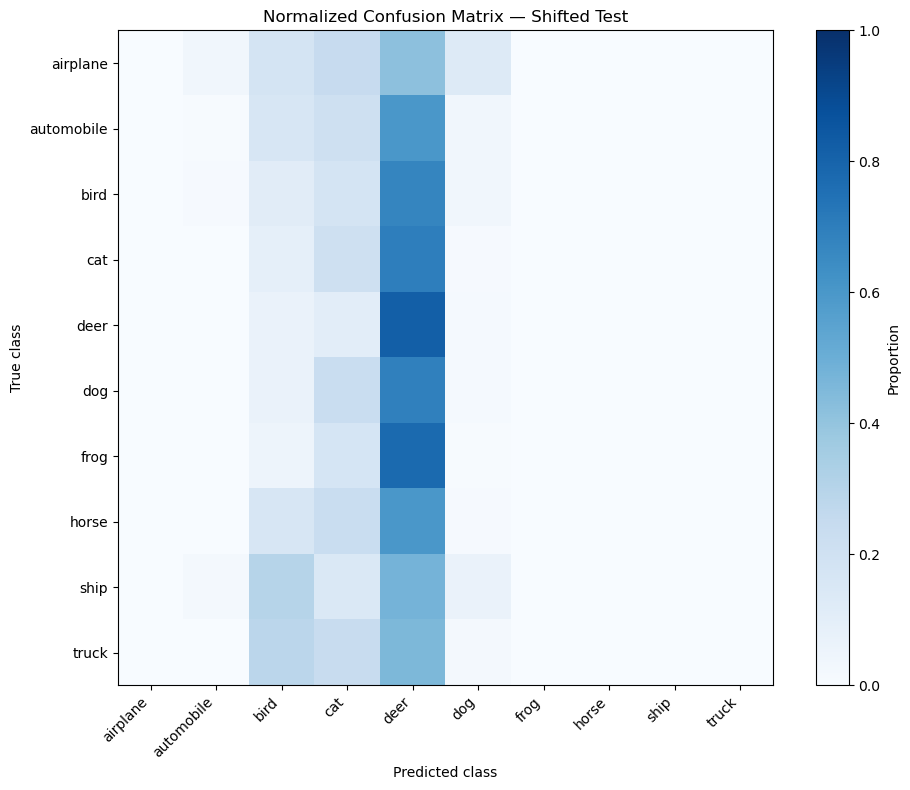

In [36]:

cm = confusion_matrix(
    y_true,
    shifted_predictions,
    labels=np.arange(10),
    normalize="true"
)

plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Proportion")
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Normalized Confusion Matrix — Shifted Test")
plt.tight_layout()
plt.show()


In [37]:

confusions = []

for true_id in range(10):
    for pred_id in range(10):
        if true_id != pred_id:
            confusions.append({
                "True Class": class_names[true_id],
                "Predicted Class": class_names[pred_id],
                "Proportion": cm[true_id, pred_id]
            })

confusion_df = pd.DataFrame(confusions).sort_values(
    "Proportion", ascending=False
)

display(confusion_df.head(10))


,True Class,Predicted Class,Proportion
58,frog,deer,0.775
30,cat,deer,0.699
49,dog,deer,0.688
21,bird,deer,0.668
12,automobile,deer,0.600
67,horse,deer,0.599
76,ship,deer,0.474
85,truck,deer,0.456
3,airplane,deer,0.417
74,ship,bird,0.297


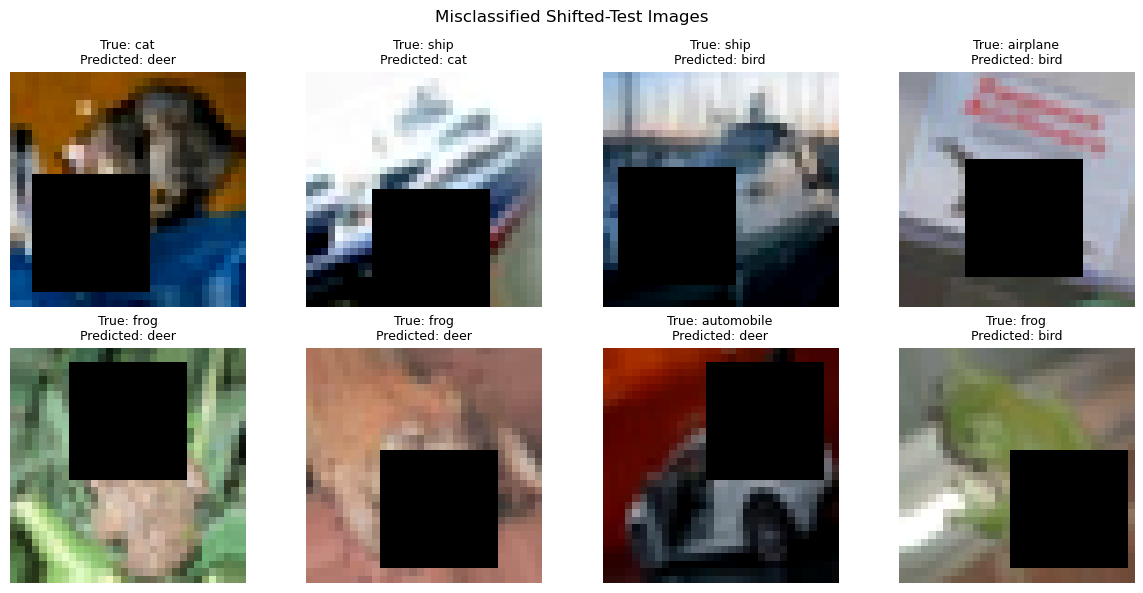

In [38]:

wrong_indices = np.where(
    shifted_predictions != y_true
)[0]

number_to_show = min(8, len(wrong_indices))

plt.figure(figsize=(12, 6))

for position, image_id in enumerate(wrong_indices[:number_to_show]):
    plt.subplot(2, 4, position + 1)

    plt.imshow(X_shifted[image_id])

    true_name = class_names[y_true[image_id]]
    pred_name = class_names[shifted_predictions[image_id]]

    plt.title(
        "True: " + true_name + "\nPredicted: " + pred_name,
        fontsize=9
    )
    plt.axis("off")

plt.suptitle("Misclassified Shifted-Test Images")
plt.tight_layout()
plt.show()


In [40]:
# Grayscale-only test set
X_hidden = np.mean(
    X_test_images.astype("float32"),
    axis=3,
    keepdims=True
)
X_hidden = np.repeat(X_hidden, 3, axis=3).astype("uint8")
hidden_results = []
for seed in seeds:
    model = saved_models[("Final model", seed)]
    _, hidden_acc = model.evaluate(
        X_hidden,
        tf.one_hot(y_test_labels, 10),
        batch_size=128,
        verbose=0
    )
    hidden_results.append(hidden_acc)
print("Grayscale-only accuracy: %.4f +/- %.4f" % (
    np.mean(hidden_results), np.std(hidden_results, ddof=0)
))

Grayscale-only accuracy: 0.1084 +/- 0.0036


In [43]:
def tta_predict(model, images, batch_size=128):
    all_predictions = []
    for start in range(0, len(images), batch_size):
        batch = tf.cast(
            images[start:start + batch_size], tf.float32
        )
        padded = tf.pad(
            batch,
            [[0, 0], [2, 2], [2, 2], [0, 0]],
            mode="REFLECT"
        )
        views = [batch, tf.image.flip_left_right(batch)]
        offsets = [(1, 2), (3, 2), (2, 1), (2, 3)]

        for top, left in offsets:
            shifted = tf.image.crop_to_bounding_box(
                padded, top, left, 32, 32
            )
            views.append(shifted)

        probabilities = []
        for view in views:
            probabilities.append(
                model(view, training=False).numpy()
            )
        average_probabilities = np.mean(
            probabilities, axis=0
        )

        all_predictions.append(average_probabilities)

    return np.concatenate(all_predictions, axis=0)
start_time = time.perf_counter()

ordinary_probabilities = final_model.predict(
    X_shifted, batch_size=128, verbose=0
)

ordinary_time = time.perf_counter() - start_time

ordinary_predictions = np.argmax(
    ordinary_probabilities, axis=1
)

ordinary_accuracy = np.mean(
    ordinary_predictions == y_shifted
)
start_time = time.perf_counter()

tta_probabilities = tta_predict(
    final_model, X_shifted
)

tta_time = time.perf_counter() - start_time

tta_predictions = np.argmax(tta_probabilities, axis=1)

tta_accuracy = np.mean(
    tta_predictions == y_shifted
)

print("Ordinary shifted accuracy:",
      round(ordinary_accuracy * 100, 2), "%")

print("TTA shifted accuracy:",
      round(tta_accuracy * 100, 2), "%")

print("Accuracy change:",
      round((tta_accuracy - ordinary_accuracy) * 100, 2),
      "percentage points")

print("Ordinary inference time:",
      round(ordinary_time, 2), "seconds")

print("TTA inference time:",
      round(tta_time, 2), "seconds")

print("Inference time multiplier:",
      round(tta_time / max(ordinary_time, 1e-9), 2))


Ordinary shifted accuracy: 11.56 %
TTA shifted accuracy: 11.59 %
Accuracy change: 0.03 percentage points
Ordinary inference time: 2.31 seconds
TTA inference time: 40.71 seconds
Inference time multiplier: 17.66
